# Novelty 1 — Joint Tweet-Level Classification and Token-Level SRL
### Tahap 1: Persiapan Data, Audit Label, dan Split Tanpa Kebocoran

Eksperimen ini menguji pendekatan **multi-task learning** dengan *shared encoder* dan dua *prediction head*:

1. **Tweet-level classification** — label kejadian (multi-label, 5 kelas).
2. **Token-level SRL classification** — label argumen per token.

**Cakupan notebook ini:** validasi dataset, pembentukan target multi-label tingkat tweet dari label token, audit kualitas anotasi (NO-EVENT dan multi-event), serta pembuatan split train/validation/test pada tingkat tweet. **Belum** ada encoder, head, maupun pelatihan model; klaim bahwa joint learning meningkatkan performa baru bisa diuji pada tahap berikutnya.

### Ringkasan temuan

| Indikator | Nilai |
| --- | --- |
| Baris token awal / setelah pembersihan | 99.206 / 99.202 (4 token kosong dibuang) |
| Tweet (grup `text_id`) | 4.150 |
| Tweet dengan ≥1 label event / NO-EVENT | 4.114 / 36 |
| Tweet multi-event | 18 (0,43% dari seluruh tweet) |
| Label event terbanyak | FALSE-EVENT, 2.281 tweet (54,96%) |
| Label event tersedikit | EARTHQUAKE-EVENT, 244 tweet (5,88%) |

> Angka pada analisis dibaca dari output notebook yang tersimpan (dijalankan di Google Colab). Setelah dijalankan ulang, pastikan angkanya tetap sama.

### Daftar isi
1. Setup · 2. Load dataset · 3. Preprocessing dan grouping · 4. Audit label · 5. Target multi-label · 6. Klasifikasi tweet dan token bukti · 7. Audit multi-event · 8. Pemisahan NO-EVENT · 9. Audit tambahan NO-EVENT · 10. Ekspor hasil · 11. Split train/val/test · 12. Peta label · 13. Kesimpulan dan langkah berikutnya

### Cara menjalankan
- **Google Colab:** jalankan berurutan; Drive akan di-mount otomatis dan path default dipakai.
- **Lokal:** atur `NOVELTY1_DATA_PATH` (lokasi `all-labeled-data.csv`) dan, jika perlu, `NOVELTY1_OUTPUT_DIR` sebelum menjalankan. Kebutuhan: `pandas`, `numpy`, `matplotlib`, `scikit-learn` (PyTorch opsional pada tahap ini).
- **Dataset** tidak disertakan di repositori ini. Gunakan dataset *Semantic Role Labeling Datasets for Crisis Event* dari sumber aslinya dan patuhi lisensinya.

## 1. Setup

In [34]:
import os
import sys
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [35]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# PyTorch belum dipakai pada tahap ini; seed tetap diset agar kompatibel
# dengan tahap pelatihan model berikutnya.
try:
    import torch

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
except ImportError:
    print("PyTorch tidak terpasang (tidak diperlukan untuk tahap persiapan data).")

PyTorch: 2.11.0+cu130
CUDA available: True
Device: cuda


In [36]:
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
DEFAULT_DATA_PATH = "data/all-labeled-data.csv"
DATA_PATH = os.environ.get("NOVELTY1_DATA_PATH", DEFAULT_DATA_PATH)

print("File tersedia:", os.path.exists(DATA_PATH))
assert os.path.exists(DATA_PATH), (
    f"Dataset tidak ditemukan di '{DATA_PATH}'. "
    "Silakan atur environment variable NOVELTY1_DATA_PATH atau letakkan file di folder data/."
)

File tersedia: True


## 2. Load Dataset

Membaca dataset berlabel yang digunakan pada Checkpoint 1.
Dataset asli tidak akan dimodifikasi.

In [38]:
df_raw = pd.read_csv(DATA_PATH, keep_default_na=False)

print("Ukuran dataset:", df_raw.shape)
print("\nNama kolom:")
print(df_raw.columns.tolist())

display(df_raw.head(10))

Ukuran dataset: (99206, 5)

Nama kolom:
['text_id', 'id', 'token', 'entity', 'argument']


,text_id,id,token,entity,argument
0,BAN-00001,BAN-00001.001,13,O,O
1,BAN-00001,BAN-00001.002,janji,O,O
2,BAN-00001,BAN-00001.003,akan,O,O
3,BAN-00001,BAN-00001.004,mencari,O,O
4,BAN-00001,BAN-00001.005,solusi,O,O
5,BAN-00001,BAN-00001.006,banjir,B-EVE,FALSE-EVENT
6,BAN-00001,BAN-00001.007,jakarta,B-LOC,PLACE-ARG
7,BAN-00001,BAN-00001.008,dan,O,O
8,BAN-00001,BAN-00001.009,kemacetan,O,O
9,BAN-00001,BAN-00001.010,jakarta,B-LOC,PLACE-ARG


In [39]:
print("Jumlah data kosong setiap kolom:")
print(df_raw.isna().sum())

print("\nJumlah token kosong:")
print(
    (df_raw["token"].astype(str).str.strip() == "").sum()
)

Jumlah data kosong setiap kolom:
text_id     0
id          0
token       0
entity      0
argument    0
dtype: int64

Jumlah token kosong:
4


**Analisis — kualitas data mentah**

- Dataset berisi **99.206 baris token** dan lima kolom: `text_id`, `id`, `token`, `entity`, `argument`. Satu baris mewakili satu token.
- `isna()` melaporkan 0 nilai kosong pada semua kolom, tetapi hasil ini **tidak menjamin data bersih**: `keep_default_na=False` membuat string seperti `""`, `NA`, atau `null` tetap dibaca sebagai teks biasa dan tidak menjadi `NaN`. Karena itu pemeriksaan terpisah terhadap token kosong/whitespace diperlukan, dan memang menemukan **4 token kosong**.
- Pemakaian `keep_default_na=False` tetap tepat: token yang kebetulan berupa `NA` atau `null` tidak hilang secara diam-diam.

## 3. Preprocessing dan Grouping Token

Token dikelompokkan berdasarkan text_id.
Urutan token, label argument, dan label entity dipertahankan.

In [40]:
df = df_raw.copy()

empty_token = df["token"].astype(str).str.strip() == ""

print("Token kosong sebelum dibersihkan:", empty_token.sum())

df = df[~empty_token].copy()

print("Jumlah baris setelah pembersihan:", len(df))

Token kosong sebelum dibersihkan: 4
Jumlah baris setelah pembersihan: 99202


In [41]:
tweets = []

for tid, group in df.groupby("text_id", sort=False):
    tokens = group["token"].astype(str).tolist()

    tweets.append({
        "text_id": tid,
        "tweet": " ".join(tokens),
        "tokens": tokens,
        "labels": group["argument"].tolist(),
        "entity": group["entity"].tolist()
    })

print("Jumlah tweet:", len(tweets))

Jumlah tweet: 4150


In [42]:
for tweet in tweets[:5]:
    print("Text ID:", tweet["text_id"])
    print("Tweet:", " ".join(tweet["tokens"]))
    print("Labels:", tweet["labels"])
    print("Entity:", tweet["entity"])
    print("-" * 70)

Text ID: BAN-00001
Tweet: 13 janji akan mencari solusi banjir jakarta dan kemacetan jakarta ketika jadi presiden bahkan statemen di 2014 akan menggunakan cara lain namun faktanya kini banyak barisan pendukung yang menyalahkan anies sandi dengan fakta jakarta masih banjir dan macet ingat janji ini
Labels: ['O', 'O', 'O', 'O', 'O', 'FALSE-EVENT', 'PLACE-ARG', 'O', 'O', 'PLACE-ARG', 'O', 'O', 'OFFICER-ARG', 'O', 'O', 'O', 'TIME-ARG', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'PLACE-ARG', 'O', 'FALSE-EVENT', 'O', 'O', 'O', 'O', 'O']
Entity: ['O', 'O', 'O', 'O', 'O', 'B-EVE', 'B-LOC', 'O', 'O', 'B-LOC', 'O', 'O', 'B-ORG', 'O', 'O', 'O', 'B-ARG', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-LOC', 'O', 'B-EVE', 'O', 'O', 'O', 'O', 'O']
----------------------------------------------------------------------
Text ID: BAN-00002
Tweet: ingin tenangkan diri di musim banjir ? -memancing -sukat air -bakar ikan -berehat di ata

In [43]:
for tweet in tweets:
    assert len(tweet["tokens"]) == len(tweet["labels"])
    assert len(tweet["tokens"]) == len(tweet["entity"])

print("Semua token dan label memiliki panjang yang sesuai.")

Semua token dan label memiliki panjang yang sesuai.


**Analisis — grouping dan alignment**

- Setelah 4 token kosong dibuang, tersisa **99.202 baris** yang membentuk **4.150 tweet** (rata-rata sekitar 23,9 token per tweet). Dataset mentah `df_raw` tidak diubah.
- Assertion panjang `tokens`, `labels`, dan `entity` lolos untuk semua tweet, sehingga tidak ada pergeseran label terhadap token.
- Teks tweet dibentuk dengan `" ".join(tokens)`. Dari contoh terlihat bahwa teks sudah **huruf kecil dan terpisah per token** (misalnya tanda baca berdiri sendiri, artefak seperti `` `` ``). Jadi ini bukan teks mentah. Pada tahap tokenisasi subword (mis. IndoBERTweet), label token harus diselaraskan ulang dengan salah satu skema: label pada *first sub-token* saja, atau label diulang ke semua sub-token.

## 4. Audit Label

Memeriksa distribusi label token yang tersedia
dan memastikan lima label kejadian dapat dikenali.

In [44]:
all_labels = Counter(
    label
    for tweet in tweets
    for label in tweet["labels"]
)

print("Distribusi label token:")

for label, count in all_labels.most_common():
    print(f"{label}: {count}")

Distribusi label token:
O: 68751
PLACE-ARG: 10227
FALSE-EVENT: 3448
STREET-ARG: 3154
AFFECTEDOBJECTS-ARG: 2789
TIME-ARG: 2424
OFFICER-ARG: 2113
INFORMATION-ARG: 1977
FIRE-EVENT: 834
REASON-ARG: 759
ACCIDENT-EVENT: 683
DEATHVICTIM-ARG: 632
EARTHQUAKE-EVENT: 579
FLOOD-EVENT: 470
WOUNDVICTIM-ARG: 362


In [45]:
EVENTS = [
    "FLOOD-EVENT",
    "FIRE-EVENT",
    "EARTHQUAKE-EVENT",
    "ACCIDENT-EVENT",
    "FALSE-EVENT"
]

for event in EVENTS:
    print(f"{event}: {all_labels.get(event, 0)}")

FLOOD-EVENT: 470
FIRE-EVENT: 834
EARTHQUAKE-EVENT: 579
ACCIDENT-EVENT: 683
FALSE-EVENT: 3448


**Analisis — distribusi label token**

- Terdapat **15 label argumen unik**: 1 label `O`, 5 label event, dan 9 label argumen (`PLACE-ARG`, `STREET-ARG`, `AFFECTEDOBJECTS-ARG`, `TIME-ARG`, `OFFICER-ARG`, `INFORMATION-ARG`, `REASON-ARG`, `DEATHVICTIM-ARG`, `WOUNDVICTIM-ARG`).
- Label `O` mendominasi: 68.751 dari 99.202 token (**69,3%**). Untuk head token-level, akurasi token akan tampak tinggi walau model hanya menebak `O`; gunakan **span/entity-level F1** dan F1 per label (tanpa `O`).
- Label argumen **tidak memiliki awalan B-/I-**, sehingga dua span bertetangga dengan label yang sama tidak dapat dipisahkan. Hal ini perlu diperhitungkan saat membuat evaluator span.
- Dari 6.014 token berlabel event, **FALSE-EVENT menyumbang 3.448 token (57,3%)**. Label argumen paling jarang adalah `WOUNDVICTIM-ARG` (362 token).

## 5. Tweet-Level Multi-Label Target

Setiap tweet direpresentasikan menggunakan lima nilai biner.
Nilai 1 berarti label kejadian ditemukan pada label token,
sedangkan nilai 0 berarti tidak ditemukan.

In [46]:
EV_IDX = {
    event: i
    for i, event in enumerate(EVENTS)
}

def tweet_target(labels):
    target = [0] * len(EVENTS)

    for label in labels:
        if label in EV_IDX:
            target[EV_IDX[label]] = 1

    return target

In [47]:
test_labels = [
    ["O", "FLOOD-EVENT", "PLACE-ARG"],
    ["O", "FIRE-EVENT", "ACCIDENT-EVENT"],
    ["O", "FALSE-EVENT"],
    ["O", "FLOOD-EVENT", "FALSE-EVENT"],
    ["O", "PLACE-ARG"],
]

expected = [
    [1, 0, 0, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 0, 0, 1],
    [1, 0, 0, 0, 1],
    [0, 0, 0, 0, 0],
]

for labels, exp in zip(test_labels, expected):
    got = tweet_target(labels)
    print(labels, "=>", got)
    assert got == exp, f"Target salah untuk {labels}: {got} != {exp}"

['O', 'FLOOD-EVENT', 'PLACE-ARG'] => [1, 0, 0, 0, 0]
['O', 'FIRE-EVENT', 'ACCIDENT-EVENT'] => [0, 1, 0, 1, 0]
['O', 'FALSE-EVENT'] => [0, 0, 0, 0, 1]
['O', 'FLOOD-EVENT', 'FALSE-EVENT'] => [1, 0, 0, 0, 1]
['O', 'PLACE-ARG'] => [0, 0, 0, 0, 0]


**Analisis — fungsi target**

`tweet_target` memberi nilai 1 pada sebuah event jika labelnya muncul **minimal sekali** di antara label token, dan mengabaikan label non-event. Contoh uji sebelumnya memakai `LOCATION-ARG`, padahal label yang ada pada dataset adalah `PLACE-ARG`; hasil fungsi tidak berubah karena label non-event memang diabaikan, tetapi contoh uji kini konsisten dengan dataset. Uji juga sekarang memakai `assert` terhadap vektor yang diharapkan, bukan hanya mencetak hasil.

# 6. Membentuk Klasifikasi Tweet dan Bukti Token Event
Selain menentukan label event pada tingkat tweet, simpan token yang memiliki label event tersebut. Dengan demikian, jika satu tweet memiliki lebih dari satu event, token bukti untuk setiap event tetap dapat ditelusuri.

In [48]:
tweet_data = []

for tweet in tweets:
    target = tweet_target(tweet["labels"])

    # Ambil token yang label argument-nya termasuk salah satu event.
    # Satu event dapat memiliki lebih dari satu token.
    event_tokens = {}
    for event in EVENTS:
        event_tokens[event] = [
            token
            for token, label in zip(tweet["tokens"], tweet["labels"])
            if label == event
        ]

    active_events = [
        event for event, value in zip(EVENTS, target)
        if value == 1
    ]

    row = {
        "text_id": tweet["text_id"],
        "tweet": tweet["tweet"],
        "tokens": tweet["tokens"],
        "labels": tweet["labels"],
        "entity": tweet["entity"],
        "event_labels": active_events,
        "jumlah_event": len(active_events),
        "classification": " + ".join(active_events) if active_events else "NO-EVENT",
        "event_tokens": event_tokens
    }

    # Simpan juga target biner untuk kebutuhan eksperimen multi-label.
    for i, event in enumerate(EVENTS):
        row[event] = target[i]

    tweet_data.append(row)

df_tweet = pd.DataFrame(tweet_data)

print("Jumlah tweet:", len(df_tweet))
display(
    df_tweet[
        ["text_id", "tweet", "event_labels", "classification", "event_tokens"]
    ].head(10)
)

Jumlah tweet: 4150


,text_id,tweet,event_labels,classification,event_tokens
0,BAN-00001,13 janji akan mencari solusi banjir jakarta da...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
1,BAN-00002,ingin tenangkan diri di musim banjir ? -memanc...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
2,BAN-00003,intensitas dan curah hujan yang tinggi telah m...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
3,BAN-00004,ayuh kita bersama menjayakan misi bantuan mang...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
4,BAN-00005,anak buah bantu set up pusat pemindahan banjir...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
5,BAN-00006,`` : video kenangan gub dki jaman old menegask...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
6,BAN-00007,laporan awalan bencana jenis kejadian : banjir...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
7,BAN-00008,anggota rela pekan sedang membantu memberi saj...,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."
8,BAN-00009,banjir di jalan pagarsih,[FLOOD-EVENT],FLOOD-EVENT,"{'FLOOD-EVENT': ['banjir'], 'FIRE-EVENT': [], ..."
9,BAN-00010,keadaan banjir di seberang jaya jam 6:45pg tadi,[FALSE-EVENT],FALSE-EVENT,"{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU..."


In [49]:
print("Jumlah tweet:", len(df_tweet))

for event in EVENTS:
    count = df_tweet[event].sum()
    percentage = count / len(df_tweet) * 100

    print(
        f"{event}: {count} tweet "
        f"({percentage:.2f}%)"
    )

Jumlah tweet: 4150
FLOOD-EVENT: 371 tweet (8.94%)
FIRE-EVENT: 654 tweet (15.76%)
EARTHQUAKE-EVENT: 244 tweet (5.88%)
ACCIDENT-EVENT: 582 tweet (14.02%)
FALSE-EVENT: 2281 tweet (54.96%)


In [50]:
print("Distribusi kombinasi label event:")
display(
    df_tweet["classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="jumlah_tweet")
)

Distribusi kombinasi label event:


,classification,jumlah_tweet
0,FALSE-EVENT,2268
1,FIRE-EVENT,642
2,ACCIDENT-EVENT,581
3,FLOOD-EVENT,365
4,EARTHQUAKE-EVENT,240
5,NO-EVENT,36
6,FIRE-EVENT + FALSE-EVENT,9
7,FLOOD-EVENT + FALSE-EVENT,2
8,FLOOD-EVENT + FIRE-EVENT,2
9,EARTHQUAKE-EVENT + FALSE-EVENT,2


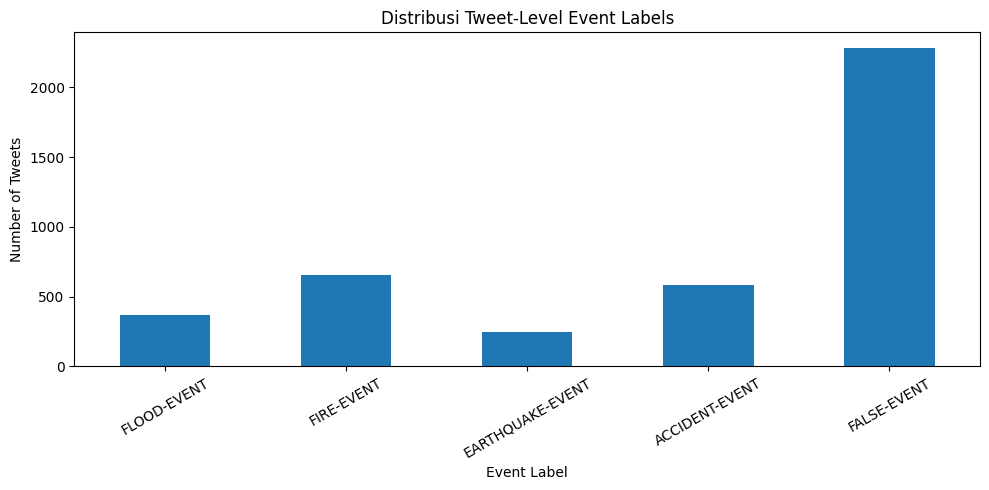

In [51]:
import matplotlib.pyplot as plt

label_counts = df_tweet[EVENTS].sum()

plt.figure(figsize=(10, 5))
label_counts.plot(kind="bar")
plt.title("Distribusi Tweet-Level Event Labels")
plt.xlabel("Event Label")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Analisis — distribusi label tweet**

| Label | Tweet | Persen dari 4.150 | Token event | Token per tweet |
| --- | --- | --- | --- | --- |
| FLOOD-EVENT | 371 | 8,94% | 470 | 1,27 |
| FIRE-EVENT | 654 | 15,76% | 834 | 1,28 |
| EARTHQUAKE-EVENT | 244 | 5,88% | 579 | 2,37 |
| ACCIDENT-EVENT | 582 | 14,02% | 683 | 1,17 |
| FALSE-EVENT | 2.281 | 54,96% | 3.448 | 1,51 |

- **Ketidakseimbangan:** FALSE-EVENT adalah label mayoritas (rasio sekitar 9,3 : 1 terhadap EARTHQUAKE-EVENT). Memprediksi FALSE-EVENT untuk semua tweet sudah memberi akurasi 54,96% pada label tersebut. Laporkan **precision, recall, dan F1 per label, serta macro-F1 dan micro-F1**; jangan hanya akurasi.
- **Hampir single-label:** jumlah label event total adalah 4.132 pada 4.114 tweet beratribut event, artinya hanya 18 label ekstra. Sebanyak **4.096 tweet (99,56% dari tweet beratribut event) hanya punya satu label event**, dan setiap tweet multi-event memiliki tepat dua label.
- **Konsekuensi:** representasi multi-hot tetap benar secara desain, tetapi evaluasi multi-label praktis hanya diwakili sekitar 18 contoh. Dengan split 10%, test set hanya memuat sekitar 2 tweet multi-event, sehingga performa pada kasus multi-event **tidak dapat disimpulkan secara statistik** dari data ini.
- Token per tweet untuk EARTHQUAKE-EVENT lebih tinggi (2,37). Dugaan yang masuk akal adalah frasa dua kata seperti "gempa bumi" yang dilabeli pada kedua token; ini dugaan, belum diverifikasi.
- Pada 10 tweet pertama, 8 berlabel FALSE-EVENT, termasuk tweet yang tampak seperti laporan kebencanaan (BAN-00007) dan tweet bantuan/relawan (BAN-00004, BAN-00005). Makna FALSE-EVENT pada pedoman anotasi perlu dipastikan sebelum label ini diperlakukan sebagai "bukan kejadian nyata". Hal ini langsung relevan bagi analisis FALSE-EVENT di tahap berikutnya.

### Distribusi label menurut sumber (prefiks `text_id`)

Prefiks `text_id` (`BAN`, `GEM`, `KEB`, `KEC`) tampaknya menandai sumber pengumpulan, kemungkinan kata kunci banjir, gempa, kebakaran, dan kecelakaan. Ini baru dugaan dari pola penamaan. Target tweet **tidak** diturunkan dari prefiks, melainkan dari label argumen; tabel berikut menunjukkan seberapa selaras keduanya.

In [52]:
df_tweet["source"] = df_tweet["text_id"].str.split("-").str[0]

source_table = df_tweet.groupby("source")[EVENTS].sum()
source_table["total_tweet"] = df_tweet.groupby("source").size()
source_table["NO-EVENT"] = (
    df_tweet[df_tweet["jumlah_event"] == 0].groupby("source").size()
    .reindex(source_table.index, fill_value=0)
)

display(source_table)

,FLOOD-EVENT,FIRE-EVENT,EARTHQUAKE-EVENT,ACCIDENT-EVENT,FALSE-EVENT,total_tweet,NO-EVENT
source,,,,,,,
BAN,369,0,2,0,877,1250,6
GEM,0,0,242,0,659,906,7
KEB,2,653,0,0,469,1128,15
KEC,0,1,0,582,276,866,8


In [53]:
sample = df_tweet.sample(
    n=min(100, len(df_tweet)),
    random_state=SEED
).copy()

display(
    sample[
        ["text_id", "tweet", "event_labels", "classification"]
    ]
)

,text_id,tweet,event_labels,classification
149,BAN-01150,assalamualaikum ketika ini saya berada di kamp...,[FALSE-EVENT],FALSE-EVENT
3030,KEC-01381,kecelakaan lalu lintas di jalur mudik turun 30 %,[FALSE-EVENT],FALSE-EVENT
720,BAN-01721,sebagian banjir sudah surut di jakarta sebagia...,[FLOOD-EVENT],FLOOD-EVENT
3839,KEB-00640,terjadi kebakaran pd rumah tinggal pkl . 2.09 ...,[FIRE-EVENT],FIRE-EVENT
3892,KEB-00693,kebakaran lahan di ogan ilir .,[FIRE-EVENT],FIRE-EVENT
...,...,...,...,...
2416,KEB-01011,polisi temukan 3 puntung rokok usai kebakaran ...,"[FIRE-EVENT, FALSE-EVENT]",FIRE-EVENT + FALSE-EVENT
1393,GEM-01393,tercatat sebanyak 388 kali gempa bumi menggunc...,[EARTHQUAKE-EVENT],EARTHQUAKE-EVENT
109,BAN-00110,tak peduli banjir jualan harus terus jalan ist...,[FALSE-EVENT],FALSE-EVENT
744,BAN-01745,seperti yang sahabat kemanusiaan ketahui bahwa...,[FALSE-EVENT],FALSE-EVENT


# 7. Audit Tweet Multi-Event
Tweet multi-event adalah tweet yang memiliki lebih dari satu label event berdasarkan anotasi token. Periksa kata/token bukti setiap event secara terpisah. Jangan menyimpulkan bahwa tweet membahas dua kejadian berbeda hanya dari banyaknya label; konteks tweet tetap perlu ditinjau.

In [54]:
df_multi_event = df_tweet[
    df_tweet["jumlah_event"] > 1
].copy()

print("Jumlah tweet multi-event:", len(df_multi_event))

display(
    df_multi_event[
        ["text_id", "tweet", "event_labels", "event_tokens", "classification"]
    ]
)

Jumlah tweet multi-event: 18


,text_id,tweet,event_labels,event_tokens,classification
524,BAN-01525,banjir landa sentani kabupaten jayapura papua ...,"[FLOOD-EVENT, FALSE-EVENT]","{'FLOOD-EVENT': ['banjir', 'banjir'], 'FIRE-EV...",FLOOD-EVENT + FALSE-EVENT
735,BAN-01736,[ pray for bengkulu ] turut berduka cita atas ...,"[FLOOD-EVENT, EARTHQUAKE-EVENT]","{'FLOOD-EVENT': ['banjir'], 'FIRE-EVENT': [], ...",FLOOD-EVENT + EARTHQUAKE-EVENT
1109,GEM-00110,ahy berikan bantuan untuk korban gempa bumi di...,"[EARTHQUAKE-EVENT, FALSE-EVENT]","{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU...",EARTHQUAKE-EVENT + FALSE-EVENT
1312,GEM-01312,bmkg mencatat 10 gempa bumi goyang indonesia s...,"[EARTHQUAKE-EVENT, FALSE-EVENT]","{'FLOOD-EVENT': [], 'FIRE-EVENT': [], 'EARTHQU...",EARTHQUAKE-EVENT + FALSE-EVENT
1656,KEB-00001,twitter please do ur magic rumah ku di kemang ...,"[FLOOD-EVENT, FIRE-EVENT]","{'FLOOD-EVENT': ['banjir', 'banjir'], 'FIRE-EV...",FLOOD-EVENT + FIRE-EVENT
1786,KEB-00131,kku gali strategi jitu tangani karhutla agar t...,"[FIRE-EVENT, FALSE-EVENT]","{'FLOOD-EVENT': [], 'FIRE-EVENT': ['karhutla']...",FIRE-EVENT + FALSE-EVENT
1887,KEB-00232,"kebakaran pasar baru dan banjir di tuban , nor...","[FLOOD-EVENT, FIRE-EVENT]","{'FLOOD-EVENT': ['banjir'], 'FIRE-EVENT': ['ke...",FLOOD-EVENT + FIRE-EVENT
2260,KEB-00855,stop kebakaran hutan dan lahan . . . kanit bin...,"[FIRE-EVENT, FALSE-EVENT]","{'FLOOD-EVENT': [], 'FIRE-EVENT': ['karhutla']...",FIRE-EVENT + FALSE-EVENT
2271,KEB-00866,kasus djoktan jadi mirip kebakaran di pabrik k...,"[FIRE-EVENT, FALSE-EVENT]","{'FLOOD-EVENT': [], 'FIRE-EVENT': ['terbakar']...",FIRE-EVENT + FALSE-EVENT
2292,KEB-00887,"innalillahi , lansia di indramayu tewas terbak...","[FIRE-EVENT, FALSE-EVENT]","{'FLOOD-EVENT': [], 'FIRE-EVENT': ['terbakar']...",FIRE-EVENT + FALSE-EVENT


In [55]:
# Tampilkan token bukti yang tidak kosong agar tiap kasus mudah ditinjau.
for _, r in df_multi_event.iterrows():
    evidence = {k: v for k, v in r["event_tokens"].items() if v}
    print(r["text_id"], "|", r["tweet"][:160])
    print("    bukti:", evidence)

BAN-01525 | banjir landa sentani kabupaten jayapura papua banjir di gunung merah membawa debit banjir dan kayu-kayu hati-hati bahaya kesetrum listrik jangan memegang tiang 
    bukti: {'FLOOD-EVENT': ['banjir', 'banjir'], 'FALSE-EVENT': ['banjir', 'banjir']}
BAN-01736 | [ pray for bengkulu ] turut berduka cita atas terjadinya bencana gempa bumi longsor dan banjir di bengkulu pada 27 april 2019
    bukti: {'FLOOD-EVENT': ['banjir'], 'EARTHQUAKE-EVENT': ['gempa', 'bumi']}
GEM-00110 | ahy berikan bantuan untuk korban gempa bumi di bayah melalui ahy foundation agus memberikan bantuan berupa sembilan bahan pokok ( sembako ) & material bangunan 
    bukti: {'EARTHQUAKE-EVENT': ['gempa', 'bumi'], 'FALSE-EVENT': ['gempa']}
GEM-01312 | bmkg mencatat 10 gempa bumi goyang indonesia selasa ( 6/11/2018 ) wilayah mana saja ? : bmkg mencatat ada 10 gempa bumi yang terjadi di wilayah indonesia kekuat
    bukti: {'EARTHQUAKE-EVENT': ['gempa', 'bumi'], 'FALSE-EVENT': ['gempa', 'bumi']}
KEB-00001 | twitt

**Analisis — tweet multi-event (18 tweet)**

- Kombinasi terbanyak adalah **FIRE-EVENT + FALSE-EVENT (9 tweet)**. Sisanya masing-masing 2 tweet (FLOOD+FALSE, FLOOD+FIRE, EARTHQUAKE+FALSE, FLOOD+EARTHQUAKE) dan 1 tweet FIRE+ACCIDENT.
- Sebagian kombinasi tampak **benar-benar memuat dua kejadian**, misalnya KEB-00232 ("kebakaran pasar baru dan banjir di tuban ...") dengan FLOOD+FIRE.
- Kombinasi **dengan FALSE-EVENT** lebih sulit ditafsirkan: sebuah tweet dapat memuat satu kata `kebakaran` yang dilabeli sebagai event nyata dan kata lain yang dilabeli FALSE-EVENT (mis. KEB-00483 yang mengulang kata `kebakaran` berkali-kali). Jika benar, anotasi berlaku pada **tingkat mention**, bukan tweet, sehingga label tweet-level yang diturunkan dari token dapat bertentangan dengan makna keseluruhan tweet. Perlu diperiksa pada token bukti, bukan disimpulkan dari jumlah label.
- Rekomendasi: audit manual 18 tweet ini; **jangan menghapus label secara otomatis**.

# 8. Pisahkan NO-EVENT dan Bentuk Dataset Hasil Klasifikasi
Sesuai instruksi, tweet yang tidak memiliki satu pun label event tidak dimasukkan ke dataset hasil klasifikasi. Data NO-EVENT tetap disimpan terpisah untuk audit dan tidak mengubah dataset mentah.

In [56]:
# Simpan tweet tanpa label event sebagai data audit.
df_no_event = df_tweet[
    df_tweet["jumlah_event"] == 0
].copy()

# Dataset hasil klasifikasi hanya berisi tweet dengan minimal satu event.
df_classified = df_tweet[
    df_tweet["jumlah_event"] > 0
].copy()

print("Jumlah tweet awal:", len(df_tweet))
print("Jumlah tweet NO-EVENT (dipisahkan):", len(df_no_event))
print("Jumlah tweet dengan event:", len(df_classified))

assert len(df_tweet) == len(df_no_event) + len(df_classified)
assert (df_classified["jumlah_event"] >= 1).all()
assert (df_no_event["jumlah_event"] == 0).all()

print("\nDistribusi klasifikasi pada dataset hasil:")
display(
    df_classified["classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="jumlah_tweet")
)

print("\nContoh tweet NO-EVENT untuk audit:")
display(
    df_no_event[["text_id", "tweet", "labels"]].head(10)
)

Jumlah tweet awal: 4150
Jumlah tweet NO-EVENT (dipisahkan): 36
Jumlah tweet dengan event: 4114

Distribusi klasifikasi pada dataset hasil:


,classification,jumlah_tweet
0,FALSE-EVENT,2268
1,FIRE-EVENT,642
2,ACCIDENT-EVENT,581
3,FLOOD-EVENT,365
4,EARTHQUAKE-EVENT,240
5,FIRE-EVENT + FALSE-EVENT,9
6,FLOOD-EVENT + FALSE-EVENT,2
7,FLOOD-EVENT + FIRE-EVENT,2
8,EARTHQUAKE-EVENT + FALSE-EVENT,2
9,FLOOD-EVENT + EARTHQUAKE-EVENT,2



Contoh tweet NO-EVENT untuk audit:


,text_id,tweet,labels
298,BAN-01299,rumah terbawa arus banjir di gowa,"[AFFECTEDOBJECTS-ARG, O, O, O, O, PLACE-ARG]"
427,BAN-01428,kopo depan rskia macet akibat banjir di citarip,"[INFORMATION-ARG, INFORMATION-ARG, INFORMATION..."
806,BAN-01807,[ garage sale ] halo sahabat tahukah kamu kond...,"[O, O, O, O, O, O, O, O, O, O, O, O, PLACE-ARG..."
831,BAN-01832,korban kebakaran banjir di jakarta enggak pern...,"[O, O, PLACE-ARG, O, PLACE-ARG, O, O, O, O]"
1079,GEM-00080,gempa bumi sedang trending di google baca beri...,"[O, O, O, O, O, O, O, O, O, O, O, O]"
1193,GEM-01193,bacaan yasin dan tahlil di masjid as-salam ked...,"[O, O, O, O, O, O, O, O, O, O, O, O, O, O, O, ..."
1555,GEM-01555,kepala pusat gempa bumi dan tsunami bmkg rahma...,"[O, OFFICER-ARG, OFFICER-ARG, OFFICER-ARG, OFF..."
1651,GEM-01651,pertama di riau gempa bumi terjadi di bangkinang,"[O, O, PLACE-ARG, O, O, O, O, O]"
1666,KEB-00011,mobil pemadam kebakaran canggih ini hanya ada ...,"[O, OFFICER-ARG, OFFICER-ARG, O, O, O, O, O, P..."
1685,KEB-00030,"liat mobil yg gmw minggir , udah gila ya pd ga...","[O, O, O, O, O, O, O, O, O, O, O, O, O, O, O, ..."


**Analisis — NO-EVENT (36 tweet)**

- NO-EVENT di sini berarti **tidak ada label event pada kolom `argument`**, bukan "isi tweet tidak membahas kejadian".
- Dari 10 contoh yang tampil, **setidaknya 7 memiliki label argumen** (mis. `PLACE-ARG`, `OFFICER-ARG`, `AFFECTEDOBJECTS-ARG`) tetapi tidak punya label event. Beberapa tampak sebagai **label event yang terlewat**: BAN-01299 ("rumah terbawa arus banjir di gowa") dan GEM-01651 ("pertama di riau gempa bumi terjadi di bangkinang") jelas menyebut kejadian.
- Sebagian lain memang wajar tanpa event: GEM-00080 (hanya "gempa bumi sedang trending di google", seluruh token `O`) dan KEB-00011 (membahas mobil pemadam kebakaran, bukan kejadian kebakaran).
- Jadi kelompok ini campuran antara **anotasi terlewat** dan **non-event yang sah**. Keputusan menghapusnya dari dataset tweet-level harus menunggu audit manual. Pada task token-level, tweet ini **masih berguna** karena membawa label argumen.

## 9. Audit Tambahan NO-EVENT

Kelompokkan 36 tweet NO-EVENT berdasarkan dua indikator otomatis, lalu sediakan kolom `audit_kategori` untuk diisi manual:

- `punya_argumen`: tweet memiliki setidaknya satu label argumen selain `O`.
- `kata_kejadian`: teks memuat kata kunci kejadian (banjir, gempa, kebakaran, kecelakaan).

Kombinasi `punya_argumen = True` dan `kata_kejadian = True` adalah kandidat kuat **label event yang terlewat**.

In [57]:
df_no_event["punya_argumen"] = df_no_event["labels"].apply(
    lambda ls: any(l != "O" for l in ls)
)
df_no_event["kata_kejadian"] = df_no_event["tweet"].str.contains(
    "banjir|gempa|kebakaran|kecelakaan", regex=True
)

# Kolom kosong untuk diisi saat audit manual, misalnya:
# label_terlewat | bukan_kejadian | kategori_lain
df_no_event["audit_kategori"] = ""

display(
    pd.crosstab(
        df_no_event["punya_argumen"],
        df_no_event["kata_kejadian"],
        margins=True,
    )
)

kandidat = df_no_event[
    df_no_event["punya_argumen"] & df_no_event["kata_kejadian"]
]
print("Kandidat label event terlewat:", len(kandidat))
display(kandidat[["text_id", "tweet"]])

kata_kejadian,True,All
punya_argumen,,
False,10,10
True,26,26
All,36,36


Kandidat label event terlewat: 26


,text_id,tweet
298,BAN-01299,rumah terbawa arus banjir di gowa
427,BAN-01428,kopo depan rskia macet akibat banjir di citarip
806,BAN-01807,[ garage sale ] halo sahabat tahukah kamu kond...
831,BAN-01832,korban kebakaran banjir di jakarta enggak pern...
1555,GEM-01555,kepala pusat gempa bumi dan tsunami bmkg rahma...
1651,GEM-01651,pertama di riau gempa bumi terjadi di bangkinang
1666,KEB-00011,mobil pemadam kebakaran canggih ini hanya ada ...
1685,KEB-00030,"liat mobil yg gmw minggir , udah gila ya pd ga..."
1907,KEB-00252,saat ini belum ada terkait penerimaan petugas ...
1923,KEB-00268,sebagai servis hp dan laptop . pihak nya langs...


## 10. Ekspor Hasil

Dua berkas disimpan terpisah: tweet dengan minimal satu label event, dan tweet NO-EVENT untuk audit. Dataset mentah tidak diubah. Berkas hasil turunan dari dataset sumber, jadi periksa lisensinya sebelum membagikannya di repositori publik.

In [58]:
OUTPUT_DIR = os.environ.get("NOVELTY1_OUTPUT_DIR", "results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASSIFIED_PATH = os.path.join(OUTPUT_DIR, "tweet_classification_with_event.csv")
NO_EVENT_PATH = os.path.join(OUTPUT_DIR, "tweet_no_event_audit.csv")

df_classified.to_csv(CLASSIFIED_PATH, index=False, encoding="utf-8-sig")
df_no_event.to_csv(NO_EVENT_PATH, index=False, encoding="utf-8-sig")

print("Dataset klasifikasi disimpan:", CLASSIFIED_PATH)
print("Data NO-EVENT untuk audit disimpan:", NO_EVENT_PATH)

Dataset klasifikasi disimpan: results/tweet_classification_with_event.csv
Data NO-EVENT untuk audit disimpan: results/tweet_no_event_audit.csv


## 11. Split Train / Validation / Test pada Tingkat Tweet

Pembagian dilakukan per `text_id`, **bukan per token**, agar token dari tweet yang sama tidak tersebar ke beberapa split (kebocoran data). Split memakai **seluruh 4.150 tweet**, termasuk NO-EVENT, karena tweet NO-EVENT masih punya label argumen untuk head token-level. Pada head tweet-level, tweet NO-EVENT dapat di-*mask* dari loss; ini keputusan desain yang harus dinyatakan pada metodologi.

Stratifikasi memakai satu kunci per tweet: label event tunggal, `MULTI-EVENT` (18 tweet), atau `NO-EVENT`. Pendekatan ini sederhana dan menjaga proporsi kelas utama; untuk stratifikasi multi-label yang lebih ketat dapat dipakai *iterative stratification* (pustaka `iterative-stratification`), tetapi dengan 99,56% tweet single-label perbedaannya kecil.

In [59]:
from sklearn.model_selection import train_test_split

def stratum(row):
    if row["jumlah_event"] == 0:
        return "NO-EVENT"
    if row["jumlah_event"] > 1:
        return "MULTI-EVENT"
    return row["event_labels"][0]

df_tweet["stratum"] = df_tweet.apply(stratum, axis=1)

# 80% train, 10% validation, 10% test
train_ids, temp_ids = train_test_split(
    df_tweet["text_id"],
    test_size=0.20,
    stratify=df_tweet["stratum"],
    random_state=SEED,
)
temp_strata = df_tweet.set_index("text_id").loc[temp_ids, "stratum"]
val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    stratify=temp_strata.values,
    random_state=SEED,
)

split_map = {}
split_map.update({t: "train" for t in train_ids})
split_map.update({t: "val" for t in val_ids})
split_map.update({t: "test" for t in test_ids})
df_tweet["split"] = df_tweet["text_id"].map(split_map)

# Verifikasi: tidak ada tumpang tindih dan semua tweet terbagi.
assert df_tweet["split"].notna().all()
assert not (set(train_ids) & set(val_ids))
assert not (set(train_ids) & set(test_ids))
assert not (set(val_ids) & set(test_ids))
assert len(train_ids) + len(val_ids) + len(test_ids) == len(df_tweet)

print(df_tweet["split"].value_counts().reindex(["train", "val", "test"]))

split
train    3320
val       415
test      415
Name: count, dtype: int64


In [60]:
# Periksa distribusi label pada tiap split (jumlah tweet dan persentase).
counts = df_tweet.groupby("split")[EVENTS].sum().reindex(["train", "val", "test"])
counts["NO-EVENT"] = (
    df_tweet[df_tweet["jumlah_event"] == 0].groupby("split").size()
    .reindex(counts.index, fill_value=0)
)
counts["MULTI-EVENT"] = (
    df_tweet[df_tweet["jumlah_event"] > 1].groupby("split").size()
    .reindex(counts.index, fill_value=0)
)
counts["total_tweet"] = df_tweet.groupby("split").size()

display(counts)

pct = counts[EVENTS].div(counts["total_tweet"], axis=0) * 100
print("Persentase tweet per label pada tiap split (%):")
display(pct.round(2))

,FLOOD-EVENT,FIRE-EVENT,EARTHQUAKE-EVENT,ACCIDENT-EVENT,FALSE-EVENT,NO-EVENT,MULTI-EVENT,total_tweet
split,,,,,,,,
train,297,523,195,465,1825,29,14,3320
val,37,65,25,58,228,4,2,415
test,37,66,24,59,228,3,2,415


Persentase tweet per label pada tiap split (%):


,FLOOD-EVENT,FIRE-EVENT,EARTHQUAKE-EVENT,ACCIDENT-EVENT,FALSE-EVENT
split,,,,,
train,8.95,15.75,5.87,14.01,54.97
val,8.92,15.66,6.02,13.98,54.94
test,8.92,15.90,5.78,14.22,54.94


In [61]:
SPLIT_PATH = os.path.join(OUTPUT_DIR, "split_text_id.csv")
df_tweet[["text_id", "split", "stratum"]].to_csv(SPLIT_PATH, index=False)
print("Split disimpan:", SPLIT_PATH)

Split disimpan: results/split_text_id.csv


**Analisis — split**

- Proporsi label pada train/val/test harus mendekati proporsi seluruh data (mis. FALSE-EVENT sekitar 55%). Periksa tabel persentase di atas.
- Kelas langka tetap kecil pada val/test: EARTHQUAKE-EVENT hanya sekitar 24 tweet per split 10%, dan tweet multi-event sekitar 2 per split. F1 pada kelas-kelas ini **berfluktuasi besar** antar seed; laporkan hasil dari beberapa seed atau gunakan validasi silang berstratifikasi.
- File `split_text_id.csv` menyimpan pembagian sehingga semua eksperimen berikutnya memakai split yang sama.

## 12. Peta Label untuk Dua Head

Simpan pemetaan label agar tahap pelatihan memakai indeks yang konsisten: 5 label event untuk head tweet-level (sigmoid, multi-label) dan 15 label token untuk head token-level (softmax).

In [62]:
TOKEN_LABELS = ["O"] + sorted(l for l in all_labels if l != "O")

label_map = {
    "event_labels": EVENTS,
    "token_labels": TOKEN_LABELS,
    "event2id": {l: i for i, l in enumerate(EVENTS)},
    "token2id": {l: i for i, l in enumerate(TOKEN_LABELS)},
}

assert len(TOKEN_LABELS) == len(all_labels)

LABEL_MAP_PATH = os.path.join(OUTPUT_DIR, "label_map.json")
with open(LABEL_MAP_PATH, "w", encoding="utf-8") as f:
    json.dump(label_map, f, ensure_ascii=False, indent=2)

print("Jumlah label token:", len(TOKEN_LABELS))
print("Peta label disimpan:", LABEL_MAP_PATH)

Jumlah label token: 15
Peta label disimpan: results/label_map.json


## 13. Kesimpulan dan Langkah Berikutnya

### Kesimpulan
Pipeline persiapan data sudah konsisten: token dikelompokkan per `text_id`, label token tetap sejajar (lolos assertion), target multi-hot lima dimensi terbentuk, dan token bukti event tersimpan untuk audit. Dari 4.150 tweet, 4.114 memiliki label event dan 36 tidak.

### Temuan yang paling berpengaruh pada desain eksperimen
1. **Ketidakseimbangan:** FALSE-EVENT 54,96% vs EARTHQUAKE-EVENT 5,88%; token `O` 69,3%. Gunakan F1 per label/macro-F1 dan span-F1, bukan akurasi.
2. **Hampir single-label:** hanya 18 tweet multi-event (semuanya dua label), terlalu sedikit untuk menyimpulkan kinerja multi-label.
3. **Kualitas anotasi:** NO-EVENT adalah campuran label terlewat dan non-event sah; kombinasi dengan FALSE-EVENT mengindikasikan anotasi per mention. Makna FALSE-EVENT perlu dipastikan dari pedoman anotasi.
4. **Label tweet diturunkan dari label token:** target tweet-level pada dasarnya adalah fungsi dari label token. Karena itu perbaikan dari joint learning dapat sebagian disebabkan oleh bocornya informasi anotasi yang sama ke dua head, bukan hanya oleh transfer representasi. Hal ini perlu dinyatakan eksplisit pada metodologi.

### Langkah berikutnya
- Audit manual 36 tweet NO-EVENT dan 18 tweet multi-event; catat hasilnya pada `audit_kategori`.
- Tentukan perlakuan NO-EVENT pada loss tweet-level (mask) dan token-level (tetap dipakai).
- Tokenisasi subword dengan penyelarasan label token.
- Bangun baseline pembanding: model tweet-level saja, model token-level saja, dan model multi-task dengan shared encoder; laporkan metrik kedua task secara terpisah, dengan beberapa seed.
- Jalankan ulang notebook dari awal di lingkungan bersih agar semua output berasal dari kode terbaru.